# Training a MicroDuck walking policy with reinforcement learning

**Authors:** Alex He  
**Knowledge level:** Beginner  
**Publication date:** November 6, 2026

This tutorial teaches omnidirectional velocity tracking for the [MicroDuck](https://github.com/pollen-robotics/microduck) robot with proximal policy optimization (PPO) on AMD GPUs.

This tutorial does not assume prior reinforcement learning or robotics background. Major concepts are explained in the [Background knowledge](#background-knowledge) section and in the context of MicroDuck training.    

## What is the problem to be solved in this tutorial?

How do you give MicroDuck a desired velocity and direction and let it decide how all 14 joints should move at each moment? For example, given “0.3 m/s forward, 0.1 m/s left, while turning counterclockwise,” it should:

- Track forward/back, left/right, and yaw commands as accurately as possible.
- Stay upright, with as few falls and as little slipping as possible.
- Produce continuous, natural gaits without frequent self-collisions or joint-limit hits.
- Keep walking despite sensor noise, actuation delay, mass variation, and external pushes.

Hand-writing control rules that cover every velocity combination for 14 joints is hard. [**Reinforcement learning (RL)**](#what-is-reinforcement-learning) lets the robot try actions in simulation, judge outcomes from reward, and gradually learn a control policy from observations to actions.

The following is a preview video for a **successful solution** to our problem. It shows MicroDucks that have finished training and walk as instructed: upright, steady, and tracking their commanded velocity with a clean, continuous gait. You will produce something similar in [Phase 2, step 2.1](#21-eval-render-the-reference-demo-on-this-machine) below.



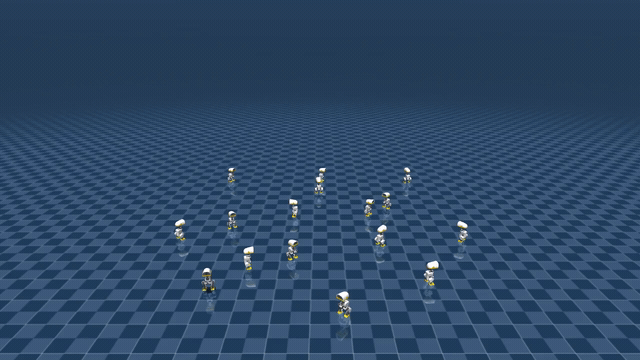



[Download a higher-quality version of the preview video.](https://raw.githubusercontent.com/rocPAI-Forge/microduck_rl_tutorial/0e515b775273f96af4b45b5eed0db886880d6ccc/notebooks/assets/_phase2.mp4)



## Prerequisites

### Hardware

**An AMD GPU:** This tutorial was tested on the following AMD GPUs. 

| Example GPU | Architecture | GPUs required |
|---|---|---|
| AMD Instinct™ MI210 | `gfx90a` | 1 |
| AMD Instinct™ MI300X | `gfx942` | 1 |
| AMD Radeon™ R9700 | `gfx1201` | 1 |
| AMD Ryzen™ AI Max (Strix Halo APU) | `gfx1151` | 1 |

The tutorial can also be run on any other AMD Instinct GPUs. Ensure your system meets the [official requirements](https://rocm.docs.amd.com/projects/install-on-linux/en/latest/reference/system-requirements.html).

### Software

**ROCm with PyTorch**: Prebuilt ROCm Docker images are provided, including a [ROCm PyTorch image](https://hub.docker.com/r/rocm/pytorch). You can use these prebuilt Docker images to save the effort of manually setting up a ROCm environment.

**Docker**: Ensure Docker is installed and configured correctly. Follow the Docker installation guide for your operating system. Skip this if you are running on a system that already has the required ROCm + Python + PyTorch stack installed.

  >**Note:** Ensure Docker permissions are correctly configured. To configure permissions for non-root access, run:
  >
  > ```bash
  > sudo usermod -aG docker $USER
  > newgrp docker
  > ```

  Verify Docker is working correctly:

  ```bash
  docker run hello-world
  ```

**Scripts and example files:** They are fetched from the tutorial repository in a cell in [Environment setup](#environment-setup).

| File | Contents | Why it is needed | Where it is used |
|---|---|---|---|
| `scripts/check_env.sh` | Python, PyTorch/ROCm, package versions, GPU name | Confirm the stack before training | Environment-check cell |
| `scripts/run_train.sh` | Wrapper around `microduck-train` with throttled notebook logs | One training entry point | [Phase 1](#phase-1-train-from-scratch-500-env-300-iter) and the optional continuation |
| `examples/velocity_flat_demo/model_950.pt` | Pretrained PPO checkpoint | A finished policy to compare with the short student run | [Phase 2](#phase-2-the-pretrained-reference-demo) evaluation and replay |


## Learning path

You are encouraged to go through the [Background knowledge](#background-knowledge) section first, and then embark on your learning path: 

| Phase | Config | What you do |
|---|---|---|
| [**Environment setup**](#environment-setup) | ROCm environment and lab workspace | Set up and check |
| [**Smoke test**](#smoke-test-4-env-2-iter) | 4 env × 2 iter | Inspect the full log and confirm the stack runs |
| [**1**](#phase-1-train-from-scratch-500-env-300-iter) | 500 env × 300 iter | Train from scratch and render a **10-second** replay |
| [**2**](#phase-2-the-pretrained-reference-demo) | Provided reference checkpoint | Replay `examples/velocity_flat_demo/model_950.pt` |
| [**3**](#phase-3-how-do-you-tell-if-the-policy-got-better) | Compare | Compare reward, episode length, curves, and video | 


> ⚠️ **Do not use the Run All button.** Run cells in order. A long training cell can sit at `[*]` while the GPU or CPU is busy. This means the cell is still running. Wait for it to finish before running the next cell.


## Background knowledge

Before starting the tutorial, it is helpful to understand the following concepts.

### Reinforcement learning and MDPs

#### What is reinforcement learning?

Reinforcement learning (RL) is a machine learning approach in which **an agent takes actions in an environment and uses feedback to improve long-term behavior.** Unlike supervised learning, the robot in the problem to be solved by this tutorial is not told the correct 14-joint action to take in each state. It receives rewards for its actions and learns better action sequences through trial and error.

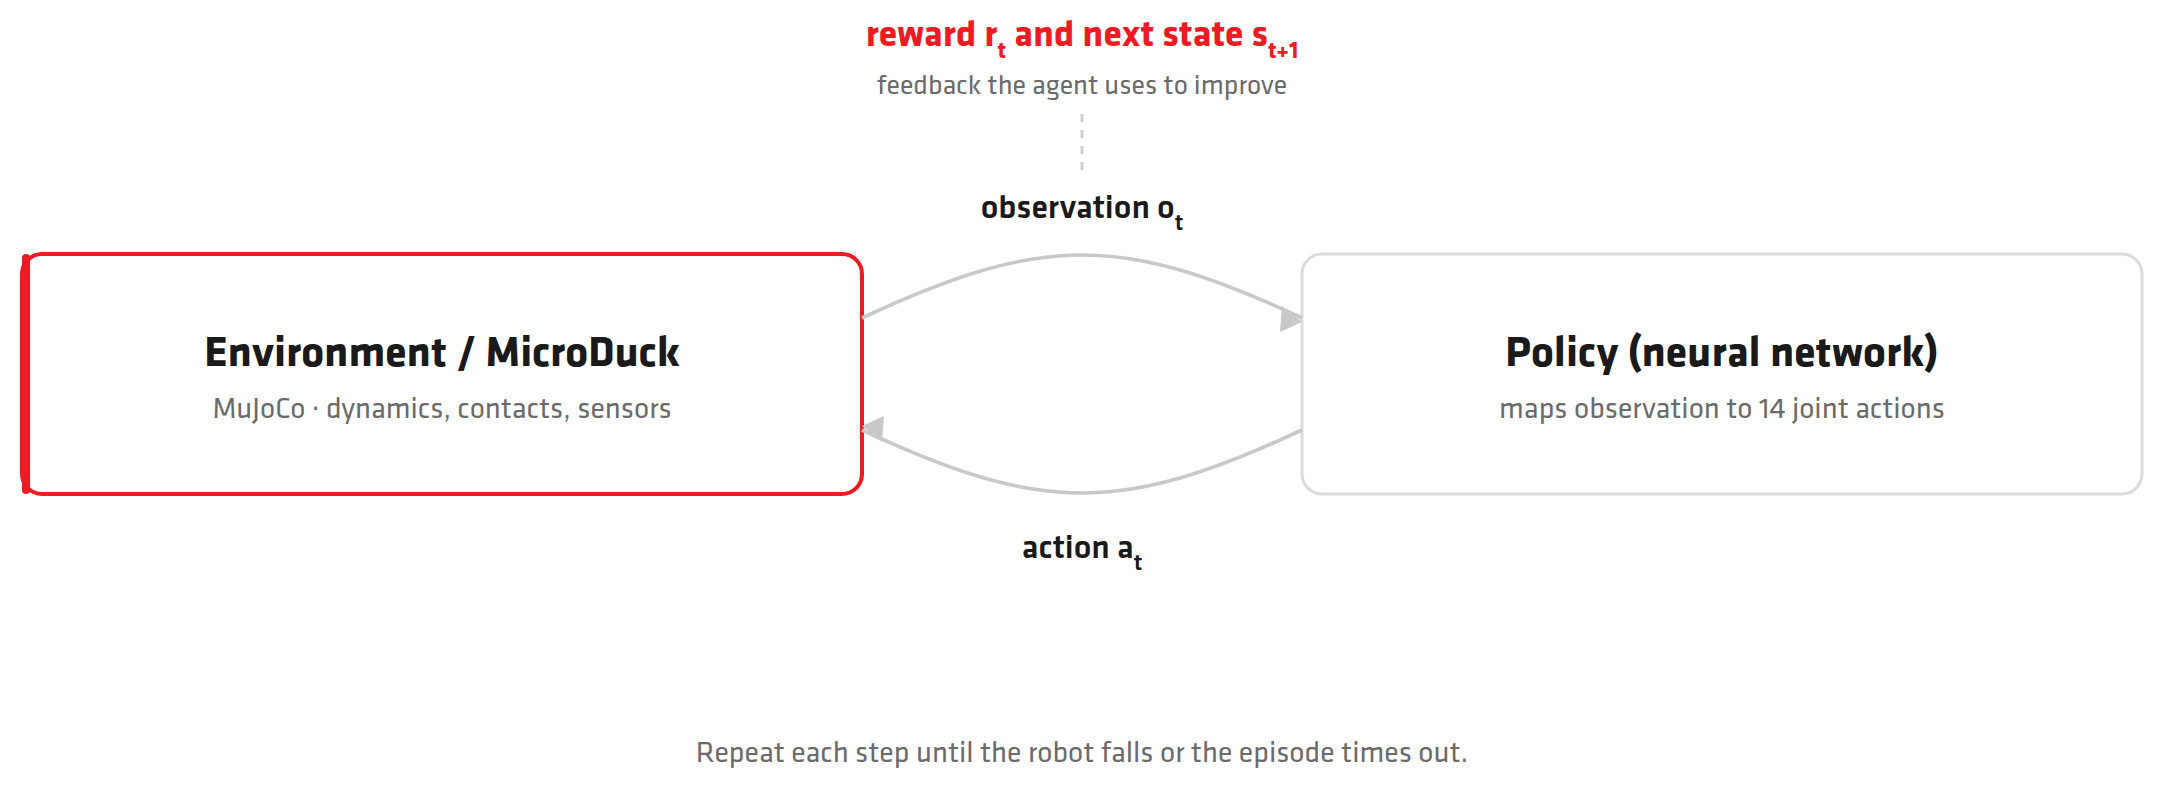



#### Why train robots with RL in simulation?

- Joints are strongly coupled; one action continues to affect later states.
- There is more than one goal: speed, balance, smoothness, energy, and safety must be traded off against each other.
- Simulation can generate millions of interactions in parallel, far more cheaply than hardware trial-and-error.
- A neural policy can learn nonlinear feedback that is hard to write by hand.

> **Note:** RL is not a magic bullet: a poorly designed reward can be exploited, simulated behavior might not transfer perfectly to real hardware, and training is stochastic. That is why replay, metrics, domain randomization, and eventual on-robot safety checks are used alongside RL.

#### What is an MDP?

RL is usually formulated as a **Markov Decision Process (MDP)**. An MDP is often written `(S, A, P, R, γ)`:

| Symbol | Meaning | MicroDuck example |
|---|---|---|
| `S` state | True situation of the world | Pose, joints, velocities, contacts, … |
| `A` action | Decision the agent can make | 14-D joint targets |
| `P` transition | How an action leads to the next state | MuJoCo (physics engine) dynamics, contacts, actuator model |
| `R` reward | How good the current outcome is | Sum of tracking, upright, gait, … terms |
| `γ` discount | How much future reward is valued | Closer to 1 means more long-horizon stability |

> **Note:** Given the current state and action, predicting the next step does not require the full history. A real robot usually sees noisy, delayed, incomplete observations `oₜ`, so code distinguishes “state” from “observation.”

#### Mapping MDP onto the RL task 

- **Command:** periodically sample `twist = (vx, vy, yaw_rate)`; ranges are about ±0.4 m/s forward/back, ±0.3 m/s lateral, ±1.0 rad/s yaw.
- **Observation:** body angular velocity, gravity direction, joint position/velocity, last action, velocity command, head command, and other terms. The actor uses a 61-D deployable observation.
- **Action:** every 20 ms the policy outputs 14-D joint targets; a better actuator models (BAM) voltage servo model turns them into actuator effort.
- **Rates:** physics at 200 Hz (`sim_dt=0.005 s`), policy at 50 Hz (`ctrl_dt=0.02 s`).
- **Episode:** at most 20 s, that is, 1000 control steps; tilt beyond ~70°, NaNs, or timeout terminate.
- **Policy:** a neural net `πθ(a|o)` with parameters `θ`. A finished `model_*.pt` stores the learned parameters.


### From common RL algorithms to PPO

#### Typical RL algorithms

| Family | Examples | Idea | Typical traits |
|---|---|---|---|
| Value-based | Deep Q-Network (DQN) | Learn action values, then pick the highest | Classic DQN fits discrete actions, not 14-D continuous joints |
| Policy gradient | REINFORCE | Directly raise the probability of high-return actions | Simple, but high-variance and sample-inefficient |
| Actor-Critic | A2C and A3C | Actor chooses actions; critic evaluates states/actions | Learns policy and value together; lowers policy-gradient variance |
| On-policy actor-critic | **PPO** | Train on data just collected by the current policy, with limited update size | Stable, mature implementations, scales to many parallel envs |
| Off-policy actor-critic | Soft Actor-Critic (SAC), Twin Delayed DDPG (TD3) | Reuse experience from a replay buffer | High sample reuse for continuous control; different tuning/system cost at large scale |

“On-policy” means that training mainly uses data from the current policy. “Off-policy” algorithms can reuse data collected by an older policy.

No algorithm is best for every task.

#### Why use PPO for MicroDuck training?

MicroDuck has 14-D continuous actions, and simulation can run hundreds to thousands of environments (envs) at once. The reasons to use PPO for this task are:

1. **Fits continuous control:** the policy can output a continuous distribution per joint.
2. **More stable training:** PPO clip limits how far the new policy may move, so one update is less likely to destroy a learned gait.
3. **Parallel sampling at scale:** 500 or 2048 envs make a large on-policy batch.
4. **Mature locomotion recipes:** many verified PPO setups exist for robot walking.
5. **Actor-critic structure:** the actor learns actions; the critic estimates future return so you can tell whether an action was better than expected.

PPO does not simply “always pick the max-reward action.” It loops:

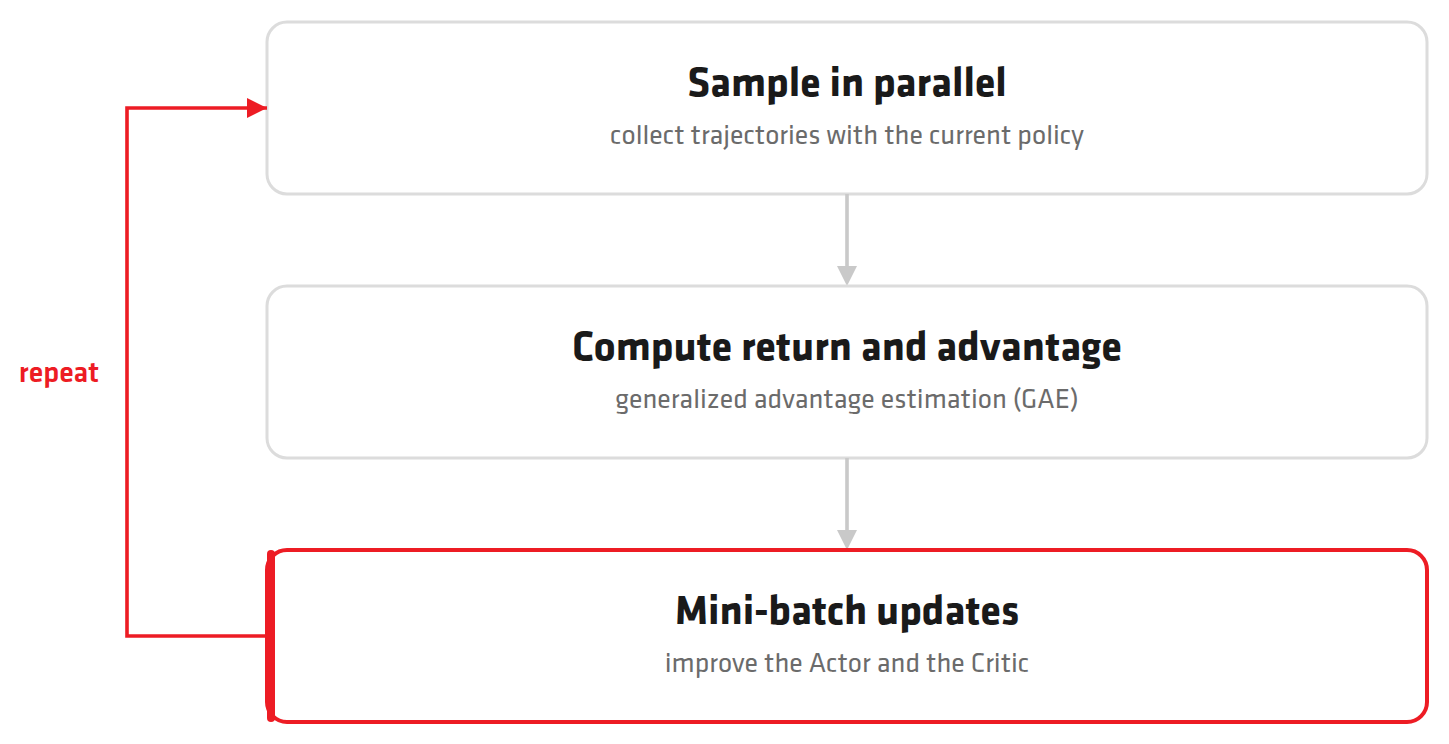



PPO involves the following key elements: 

- **Return:** discounted reward accumulated from the current time.
- **Value:** the critic’s prediction of future return.
- **Advantage:** how much better the outcome was than the critic expected.
- **PPO clip:** if the new policy changes too much vs the old one, truncate that optimization gain, “don’t step too far at once.”
- **Entropy:** keep some exploration so the policy does not become fully deterministic too early.

This training task uses an **asymmetric actor-critic**: the actor sees only the deployable 61-D noisy observation; during training the critic also sees foot contacts, foot height, and body linear velocity (76-D total). Extra information helps the critic evaluate training data more accurately, but deployment does not need those privileged observations.

<details>
<summary><strong>Advanced:</strong> PPO hyperparameters used here</summary>

- Actor/Critic multilayer perceptron (MLP): `[512, 256, 128]`, exponential linear unit (ELU)
- PPO clip: `0.2`; discount `gamma=0.99`; GAE `lambda=0.95`
- 5 epochs per batch, split into 4 mini-batches
- Initial action-noise std `1.0`, entropy coefficient `0.01`
- Adaptive learning rate, target KL divergence `0.01`
- Left-right symmetric mirror loss, coefficient `0.5`

Together these affect update stability, exploration, and compute. Do not casually change many of them in one experiment.

</details>

#### What does one iteration do?

1. Each parallel env runs the current policy for **24 control steps**.
2. Record `(observation, action, reward, terminated, value estimate)`.
3. Gather all transitions, e.g. `500 × 24 = 12,000` per round in Phase 1.
4. Compute advantage and update Actor/Critic on the GPU.
5. Write logs, save a checkpoint if needed, then start the next round.

This tutorial uses **Hydra parameters** to configure training and evaluation. The key parameters you will use are:

| Hydra parameter | Meaning |
|---|---|
| `algo.num_envs` | Independent simulations running at once |
| `algo.max_iterations` | How many sample-and-update loops |
| `algo.save_interval` | Save a checkpoint every N iterations |
| `training.no_play=true` | Do not auto-replay after training |
| `training.play_steps` | How many 50 Hz control steps to run at eval |
| `training.log_root` | Root directory for logs and checkpoints |


### Reward, domain randomization, and curriculum

#### What is a reward function?

A reward function turns “how the robot should behave” into a scalar at every step. The policy maximizes long-horizon return:

`total reward = task reward + posture/gait reward − cost of unsafe or jerky behavior`

Reward is not a human demonstration and not a success rate. A value of 94 does not mean 94% correct. Values are comparable only under the **same task and same reward definition**.

Omnidirectional MicroDuck walking cannot reward forward speed alone, or the robot could score by falling and sliding. The real task uses multiple objectives:

| Design goal | Representative term | Weight direction | What it prevents |
|---|---|---|---|
| Track planar velocity | `tracking_lin_vel` | `+2.0` | Ignoring `(vx, vy)` or only one direction |
| Track yaw rate | `tracking_ang_vel` | `+2.0` | Not turning with yaw-rate |
| Stay upright | `upright` | `+2.0` | Tilting or lying down to “farm speed” |
| Track head pose | `head_pose_tracking` | `+2.0` | Body walks while the head is uncontrolled |
| Reasonable leg pose | `leg_pose` | `+1.0` | Bizarre joint configurations |
| Reasonable air time | `air_time` | `+3.0` | Dragging feet or no real gait |
| Foot height / slip | `foot_clearance -2.0`, `foot_swing_height -0.25`, `foot_slip -0.1` | penalty | Too high or low swing, sliding on contact |
| Safety and smoothness | self-collision `-1.0`, joint limits `-1.0`, action change `-0.1` | penalty | Hitting itself, slamming limits, jitter |
| Body stability | body angular velocity `-0.05`, angular momentum `-0.02` | penalty | Violent upper-body motion |

**Reward design is a multi-objective trade-off:** too much tracking can yield a brutal gait, or too much smoothness can make the robot refuse to move. Look at total reward, per-term rewards, episode length, **and** replay video, not a single number.

#### What is domain randomization?

Mass, friction, sensors, and actuators in simulation are more ideal than on hardware. **Domain randomization** randomly changes those conditions per environment during training so the policy works for a family of possible worlds, not just one exact parameter set.

Examples in this training task:

- Observation noise and inertial measurement unit (IMU) bias
- ~20 ms joint-velocity delay
- Battery voltage, load sag, command delay, and actuator friction variation
- Robot mass/inertia, center of mass (CoM), joint initialization, and foot friction
- Random pushes every 3-6 s to train disturbance recovery

The main goal is **robustness** and a smaller sim-to-real gap. It does not erase model error and does not replace hardware tests, action limits, or emergency stop (e-stop).

<details>
<summary><strong>Advanced:</strong> Domain randomization vs. curriculum learning</summary>

Domain randomization is not curriculum learning:

- **Domain randomization** answers “what random world is each env?”
- **Curriculum learning** answers “when does difficulty increase?”

This task gradually strengthens action-change penalties, widens head-command/CoM randomization, and raises the fraction of stand-still commands. Curriculum advances by env control steps. Because each PPO iteration rolls out 24 steps, `12000 steps` in the configuration is about `500 iterations`. Raising `num_envs` increases samples per round; it does not by itself advance one environment’s curriculum.

</details>






## Environment setup

Follow these steps to set up the environment, launch the Jupyter Notebook, and install the required software.

### Provision the ROCm/JupyterLab container

> **Note:** This tutorial runs in a ROCm PyTorch Docker container with access to a ROCm-capable AMD GPU. If this container and JupyterLab environment have already been provided for you, skip ahead to [Check the active ROCm environment](#check-the-active-rocm-environment). Otherwise, complete the following steps to create and start the container.

Launch the Docker container from your host machine: 

On the **host**, save this notebook (available at [AI Developer Hub GitHub repository](https://github.com/ROCm/gpuaidev/blob/main/docs/notebooks/fine_tune/microduck_lab_standalone.ipynb)) in a directory and run:

```bash
mkdir -p runs
docker pull rocm/pytorch:rocm7.2.4_ubuntu24.04_py3.12_pytorch_release_2.10.0
docker run --rm -it --name microduck-lab \
  --device=/dev/kfd --device=/dev/dri --group-add video \
  --ipc=host --shm-size=8g \
  -p 127.0.0.1:8888:8888 \
  -v "$PWD:/workspace/lab" -v "$PWD/runs:/workspace/runs" \
  -w /workspace/lab \
  rocm/pytorch:rocm7.2.4_ubuntu24.04_py3.12_pytorch_release_2.10.0 bash
```

Inside the **container**, install the system libraries and JupyterLab, then start the server. The notebook's workspace cell installs the remaining Python training packages and checks out the two pinned repositories.

```bash
apt-get update && apt-get install -y --no-install-recommends \
  git curl ca-certificates ffmpeg \
  libosmesa6 libgl1 libgl1-mesa-dri libglfw3 libxcursor1 libxi6 libxinerama1
python3 -m pip install --no-cache-dir jupyterlab 'jupyter_server>=2.21.1'
python3 -c 'import torch; assert torch.version.hip, "ROCm PyTorch is required"'
jupyter lab --ip=0.0.0.0 --port=8888 --no-browser --allow-root \
  --notebook-dir=/workspace/lab
```

JupyterLab prints a URL with an access token. Open `http://127.0.0.1:8888/lab?token=...` on the host and select this notebook. For a remote GPU host, forward port 8888 over SSH and open the forwarded local URL. `docker exec microduck-lab jupyter server list` displays the tokenized URL again.


### Check the active ROCm environment

Start this tutorial (available at [AI Developer Hub GitHub repository](https://github.com/ROCm/gpuaidev/blob/main/docs/notebooks/fine_tune/microduck_lab_standalone.ipynb)) in JupyterLab in the provisioned container. The cell below shows the environment used by this notebook's Python kernel. Confirm HIP is available and at least one GPU is visible before continuing.



In [ ]:
import os
import platform
import sys

import torch
from IPython.display import Markdown, display


def _os_name():
    values = {}
    with open('/etc/os-release', encoding='utf-8') as release:
        for line in release:
            if '=' in line:
                key, value = line.strip().split('=', 1)
                values[key] = value.strip('"')
    return values.get('PRETTY_NAME', platform.platform())


gpu_count = torch.cuda.device_count()  # ROCm PyTorch uses the torch.cuda API.
rows = [
    ('Operating system', _os_name()),
    ('Python', sys.version.split()[0]),
    ('Kernel Python', sys.executable),
    ('PyTorch', torch.__version__),
    ('ROCm / HIP', torch.version.hip or 'unavailable'),
    ('Visible AMD GPUs', str(gpu_count)),
]
rows += [(f'GPU {index}', torch.cuda.get_device_name(index)) for index in range(gpu_count)]
display(Markdown('| Component | Active environment |\n|---|---|\n' +
                 '\n'.join(f'| {name} | `{value}` |' for name, value in rows)))
if not torch.version.hip or gpu_count < 1:
    raise RuntimeError('This notebook needs HIP-enabled PyTorch and a visible AMD GPU. Check the Jupyter kernel and container GPU access.')



### Prepare the tutorial workspace

Run the next cell once before training. It creates `microduck_workspace/` beside this notebook, checks out the MicroDuck task and tutorial support files at pinned commits, and installs the Python training packages into the **current Jupyter kernel's virtual environment**. The official container already supplies ROCm PyTorch; the cell checks that it remains available after installation. Downloading and installing the packages can take several minutes.



In [ ]:
import importlib
import os
import subprocess
import sys
from pathlib import Path

import torch


WORKSPACE = Path.cwd() / 'microduck_workspace'
TASK_ROOT = WORKSPACE / 'microduck_rl_unilab'
LAB_ROOT = WORKSPACE / 'microduck_rl_tutorial'
LOG_ROOT = Path('/workspace/runs')
TASK_SHA = '20fb528fa6c4a9559155b33e5304568668c7b7e2'
LAB_SHA = '0e515b775273f96af4b45b5eed0db886880d6ccc'


def _run(*args):
    subprocess.run(args, check=True)


def _checkout(repo, dest, sha, sparse=None):
    if not dest.exists():
        command = ['git', 'clone', '--filter=blob:none', '--no-checkout']
        if sparse:
            command.append('--sparse')
        _run(*command, repo, str(dest))
        _run('git', '-C', str(dest), 'fetch', '--depth', '1', 'origin', sha)
        if sparse:
            _run('git', '-C', str(dest), 'sparse-checkout', 'set', *sparse)
        _run('git', '-C', str(dest), 'checkout', '--detach', sha)
    if not (dest / '.git').exists():
        raise RuntimeError(f'Expected a Git checkout at {dest}')
    actual = subprocess.check_output(['git', '-C', str(dest), 'rev-parse', 'HEAD'], text=True).strip()
    if actual != sha:
        raise RuntimeError(f'{dest} is at {actual}; expected {sha}')


WORKSPACE.mkdir(parents=True, exist_ok=True)
LOG_ROOT.mkdir(parents=True, exist_ok=True)
_checkout('https://github.com/rocPAI-Forge/microduck_rl_unilab.git', TASK_ROOT, TASK_SHA)
_checkout('https://github.com/rocPAI-Forge/microduck_rl_tutorial.git', LAB_ROOT, LAB_SHA,
          sparse=['scripts', 'examples/velocity_flat_demo'])
if not (LAB_ROOT / 'scripts' / 'run_train.sh').is_file():
    raise RuntimeError('Lab training script is missing from the pinned checkout')
if not (LAB_ROOT / 'examples' / 'velocity_flat_demo' / 'model_950.pt').is_file():
    raise RuntimeError('Reference checkpoint is missing from the pinned checkout')

requirements = [
    'matplotlib', 'pandas', 'tensorboard',
    'unilab[mujoco]==1.0.0', 'unilab-rl==1.0.0', 'unisim-core==1.0.0',
    'torch==2.10.0', 'tensordict==0.14.3',
]
_run(sys.executable, '-m', 'pip', 'install', '--no-cache-dir', *requirements)
_run(sys.executable, '-m', 'pip', 'install', '--no-cache-dir', '--no-deps', '-e', str(TASK_ROOT))
importlib.invalidate_caches()
if not torch.version.hip or torch.cuda.device_count() < 1:
    raise RuntimeError('ROCm PyTorch or GPU access is unavailable after package installation')

os.environ.update({
    'LAB_ROOT': str(LAB_ROOT),
    'MICRODUCK_ROOT': str(TASK_ROOT),
    'LAB_LOG_ROOT': str(LOG_ROOT),
    'UNILAB_EXTRA_REGISTRY_PACKAGES': 'microduck_rl_unilab.tasks',
    'MUJOCO_GL': 'osmesa',
    'PYOPENGL_PLATFORM': 'osmesa',
})
scripts_dir = str(LAB_ROOT / 'scripts')
if scripts_dir not in sys.path:
    sys.path.insert(0, scripts_dir)
for script in (LAB_ROOT / 'scripts').glob('*.sh'):
    script.chmod(0o755)
print('Workspace:', WORKSPACE)
print('Task commit:', TASK_SHA)
print('Lab support commit:', LAB_SHA)
print('ROCm PyTorch:', torch.__version__, 'HIP:', torch.version.hip)
print('Ready for the environment check and training cells below.')



### Software stack and environment check

#### How do the pieces fit together?

The following diagram shows how the components work together during training. 

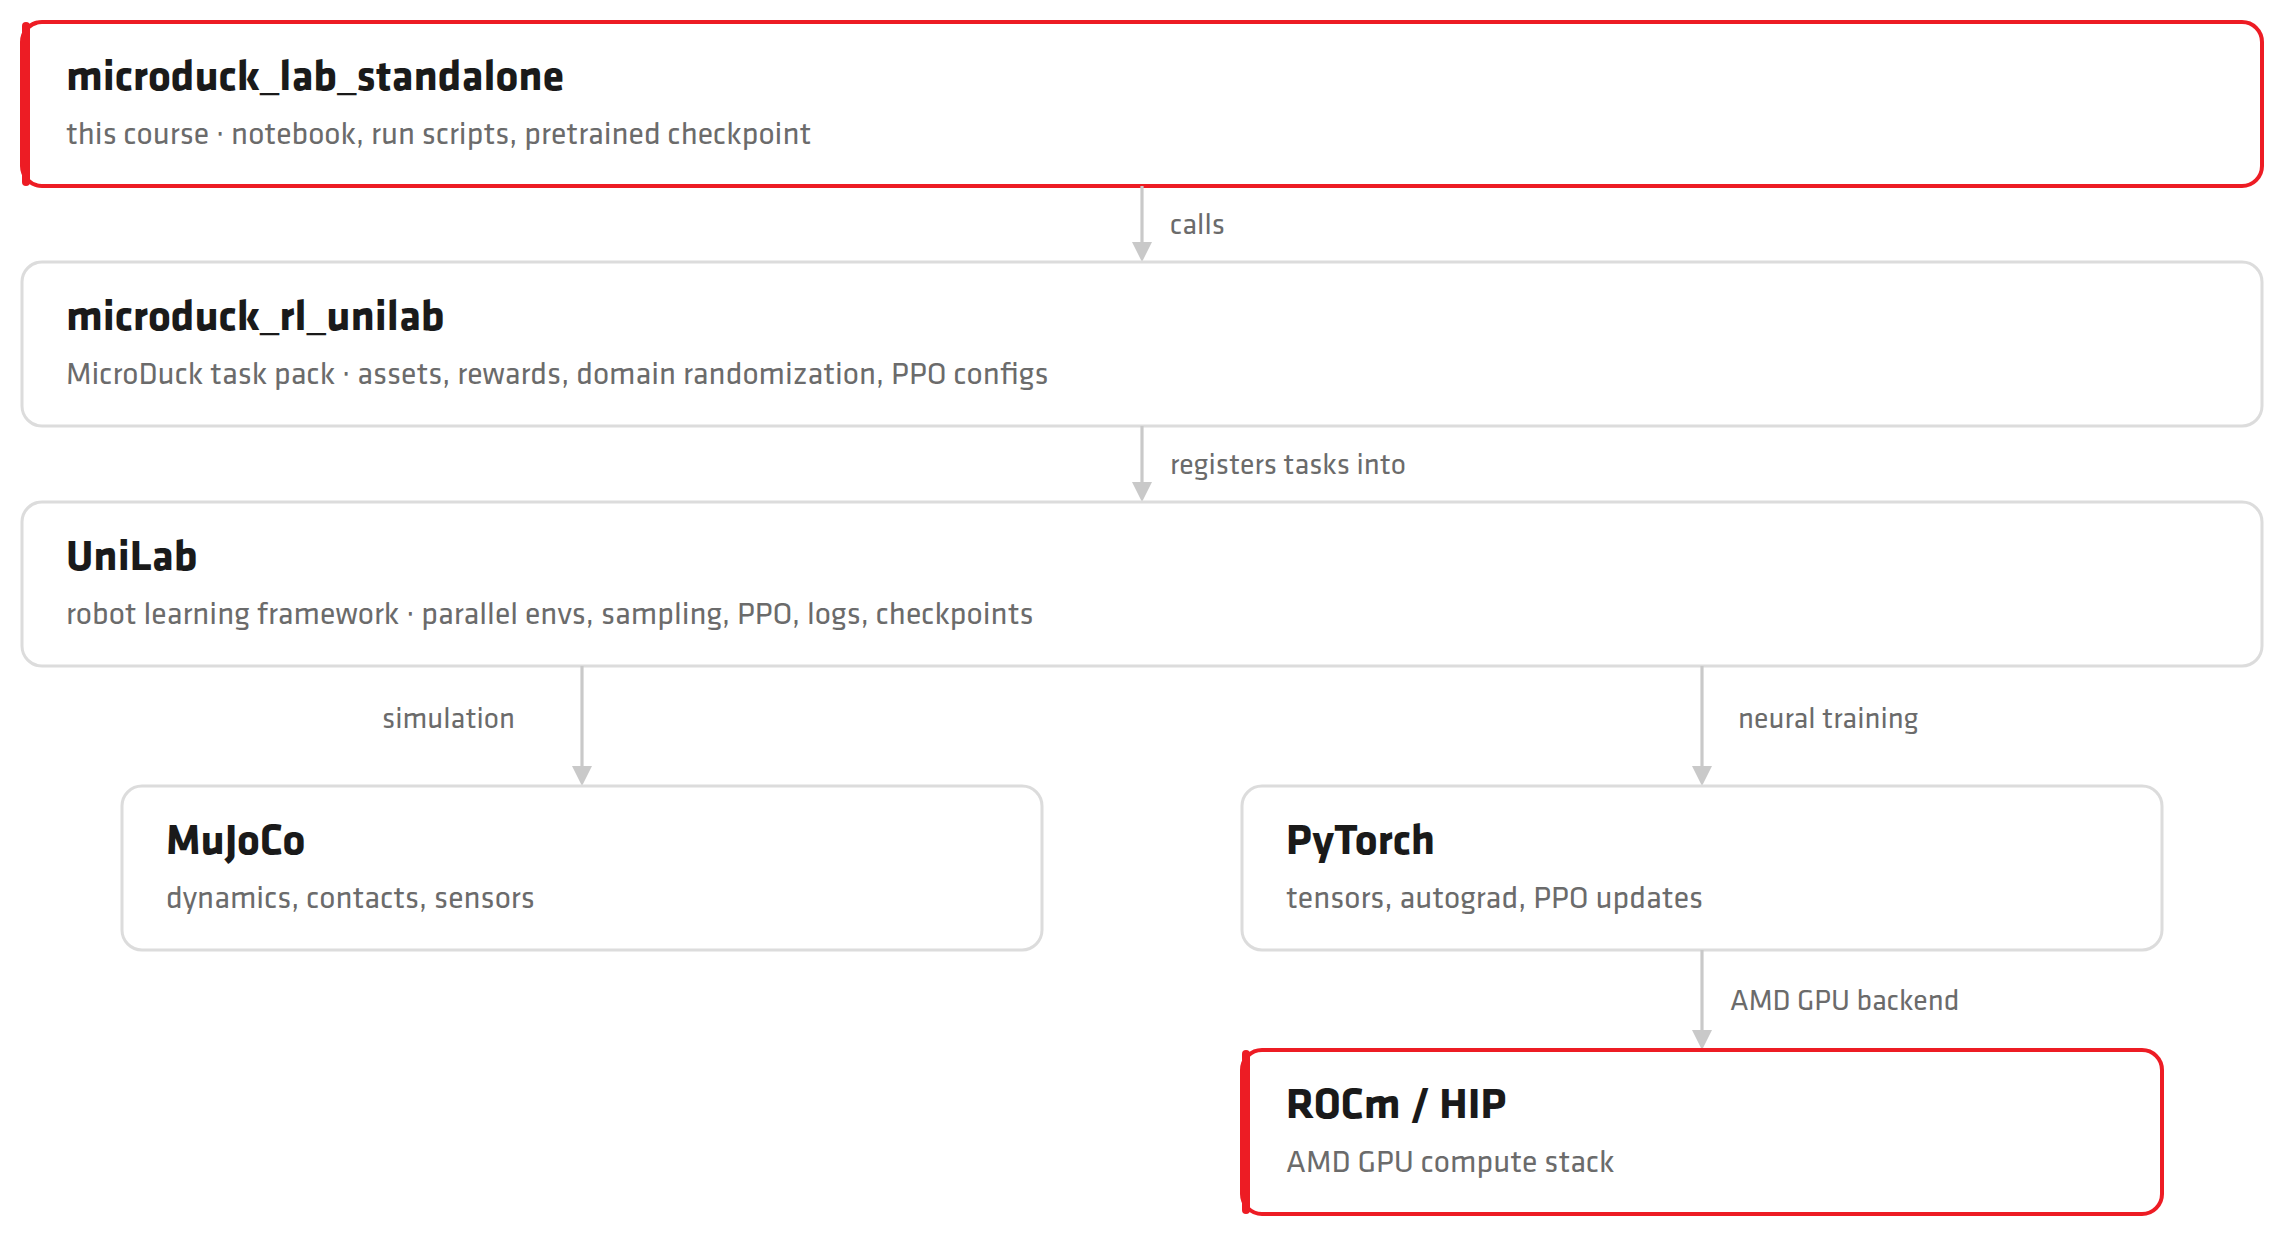



#### Open-source projects this tutorial depends on

The following table lists a number of open-source projects this tutorial uses.

| Project | Repo | Role | How this tutorial uses it |
|---|---|---|---|
| **UniLab** | [`Motphys/UniLab`](https://github.com/Motphys/UniLab) | General robot RL framework: unified env APIs, parallel sampling, algorithms, logging, checkpoints, visualization, and multiple sim/compute backends | Creates MuJoCo envs, runs PPO rollouts/updates, saves training artifacts, and provides evaluation and playback |
| **microduck_rl_unilab** | [`rocPAI-Forge/microduck_rl_unilab`](https://github.com/rocPAI-Forge/microduck_rl_unilab) | MicroDuck task pack on UniLab: robot assets, better actuator models (BAM), obs/action defs, rewards, commands, domain randomization, curriculum, and task configs | Supplies `microduck_velocity_flat`, 61-D actor observations, 14-D actions, and the training contract behind the reference demo |

Both projects use the Apache-2.0 license. Think of them as: **UniLab is the generic training base; `microduck_rl_unilab` implements MicroDuck's concrete learning task on that base.** This repository sits on top and organizes the teaching flow and pretrained assets.

Here are some common mix-ups regarding these projects:

- **ROCm is not an RL framework**: it lets PyTorch run on AMD GPUs.
- **PyTorch does not contain the MicroDuck task**: it handles networks and optimization.
- **UniLab is not the robot model**: it provides generic training and simulation management.
- **`microduck_rl_unilab` defines this tutorial's robot, rewards, and task config.**
- **`microduck_rl_tutorial` is the teaching layer**: it does not reimplement PPO; it organizes experiments and notebooks.
- This tutorial uses `--sim mujoco`. MuJoCo computes robot dynamics; PyTorch/ROCm run the policy network and PPO updates. Those jobs are different.

The tutorial uses HIP-enabled PyTorch from the official ROCm image and MuJoCo for simulation.

#### Component locations inside the container

| Component | Location |
|---|---|
| ROCm PyTorch and the Jupyter kernel | `/opt/venv` in the official image |
| Notebook | `/workspace/lab` |
| Tutorial workspace | `/workspace/lab/microduck_workspace` |
| MicroDuck task | `/workspace/lab/microduck_workspace/microduck_rl_unilab` |
| Tutorial scripts and reference model | `/workspace/lab/microduck_workspace/microduck_rl_tutorial` |
| Training and evaluation outputs | `/workspace/runs` |

The workspace cell sets `UNILAB_EXTRA_REGISTRY_PACKAGES` and `MICRODUCK_ROOT` for task registration. Run the check below and confirm HIP, the task, and the reference checkpoint are available.

#### Comparing the two policies in this tutorial

[Phase 1](#phase-1-train-from-scratch-500-env-300-iter) trains a student policy from scratch; [Phase 2](#phase-2-the-pretrained-reference-demo) loads a pretrained reference policy. Compare their evaluation videos and training budgets. Their scores use different measures.

| | Phase 1: your student run | Phase 2: provided reference |
|---|---|---|
| Checkpoint | `model_299.pt`, produced by this notebook | `model_950.pt`, loaded from the pinned upstream repository |
| Training budget | 500 env × 300 updates | 2048 env × 951 updates, including directional fine-tuning |
| Samples / iteration | 12,000 | 49,152 |
| Env steps at checkpoint | ~3.6M | **46,743,552** |
| What is measured | PPO reward, episode length, and replay video | Fixed-command six-direction selection score **81.9 / 100** (seed 123) and replay video |

The `950` in `model_950.pt` is a zero-based checkpoint index: updates 0 through 950 make **951 updates**. Each update gathers 24 steps in 2048 environments, so `2048 × 24 × 951 = 46,743,552` environment steps.

The tutorial includes `model_950.pt` to show a more capable reference PPO policy produced with more parallel environments, more training updates, and directional fine-tuning. You can explore this yourself by increasing `algo.num_envs` and `algo.max_iterations` in the Phase 1 training cell, then evaluating the resulting checkpoint; expect more GPU time and memory use. Changing those two settings alone does not reproduce the exact reference training recipe. Compare the replay videos and behavior: your run's PPO reward and the reference's six-direction selection score are different metrics.

`2048 env` means more experience is collected in parallel per iteration. It is a sample-budget choice. The policy interface is: actor observation **61-D**, critic observation **76-D**, action **14-D**.


#### Environment check

The following cell runs the tutorial's `check_env.sh`. Confirm it reports **HIP available**, that the `microduck_velocity_flat` task registers, and that the reference checkpoint is found. If any of those fail, the training and eval cells further down do not work.

In [ ]:
!bash "$LAB_ROOT/scripts/check_env.sh"

## Smoke test (4 env × 2 iter)

The smoke test runs only 2 iterations to verify ROCm/PyTorch, task registration, MuJoCo XML, sampling, PPO updates, and checkpoint writes.

Run the following cell to perform the smoke test. Unlike later phases, this cell prints the full, unfiltered output directly below the cell instead of writing it to a log file. Watch for:

- `Learning iteration 0/2`: current training round
- `Mean reward`: average cumulative reward of recent episodes; low early on is normal.
- `Mean episode length`: average surviving control steps; very short usually means frequent falls.
- `Collection time / Learning time`: sampling vs network-update time
- `ETA`: remaining time at the current pace.


In [ ]:
%%bash
set -euo pipefail
cd "${MICRODUCK_ROOT}"

# Only 2 iter: keep the full raw microduck-train output so log fields are visible.
microduck-train --algo ppo --task microduck_velocity_flat --sim mujoco \
  algo.num_envs=4 algo.max_iterations=2 training.no_play=true \
  training.logger=tensorboard training.log_root="${LAB_LOG_ROOT}"


## Phase 1 Train from scratch (500 env × 300 iter)

**Goal:** complete a medium-scale PPO run yourself and observe a policy that is “learning, but not fully trained.”

| Parameter | Value | Beginner reading |
|---|---|---|
| `algo.num_envs` | 500 | 500 independent MicroDuck simulations at once |
| `algo.max_iterations` | 300 | Repeat 300 times: “sample 24 steps → update the net” |
| `algo.save_interval` | 50 | Save every 50 iter so a crash does not wipe everything |
| `LAB_LOG_EVERY` | 10 | Notebook refreshes a summary every 10 iter |

Full training output goes to `/workspace/runs/logs/phase1_500x300.log`. The notebook keeps a single concise status refresh. Watch the overall trend of reward and episode length (these metrics do not rise monotonically).

A cell that remains at `[*]` means training is running. Training is finished when the log reaches the planned iteration and `ETA` is `0:00:00`.


In [ ]:
%%bash
set -euo pipefail
export LAB_TRAIN_LOG="${LAB_LOG_ROOT}/logs/phase1_500x300.log"
export LAB_LOG_EVERY=10
bash "${LAB_ROOT}/scripts/run_train.sh" \
  --algo ppo --task microduck_velocity_flat --sim mujoco \
  algo.num_envs=500 algo.max_iterations=300 algo.save_interval=50 \
  training.no_play=true training.logger=tensorboard training.log_root="${LAB_LOG_ROOT}"


### 1.1 How to read the one-line log after training

A sample line in the log:

```text
[train] iter  299/300 | reward    4.59 | ep  78.59 |  0:03:59 | ETA  0:00:00 | 0.80s/iter
```

The following table explains each field in the line:

| Field | Meaning | How to read this run |
|---|---|---|
| `iter 299/300` | PPO iterations are 0-indexed; `299` is the 300th sample+update | Planned 300 iter finished |
| `reward 4.59` | Mean cumulative reward of recently finished episodes; tracking, stability, smoothness, energy, etc., combined, not a 0-100 score | Compare only with the same task and reward |
| `ep 78.59` | Mean episode length: control steps before fall or timeout | At 50 Hz this is `78.59 ÷ 50 ≈ 1.57 s`, so episodes still end early |
| `0:03:59` | Elapsed time printed by the trainer | Progress of this run, not a hardware result |
| `ETA 0:00:00` | Remaining time at the recent pace | Almost done |
| `0.80s/iter` | Average time per PPO iteration printed by the trainer | A trainer counter, not a policy-quality score |

#### If reward keeps going up, is training necessarily getting better?

**A rising long-term trend is a good sign, but a single bump or short-term noise does not prove the policy improved.** PPO samples randomly, so reward is not monotonic. It can also dip when the training curriculum gets harder, or look high because of reward hacking.

Judge training by all of the following:

- **Reward trend:** tens of iterations, not the last point
- **Episode length:** whether it approaches 1000 steps (~20 s cap on this task)
- **Eval video:** upright, tracking commands, without obvious slip, jitter, or heading error

In this example, `reward=4.59, ep=78.59` means the 300-iteration policy learned *something*, but episodes end after ~1.57 s. Use your own reward, episode length, and replay video to judge your run. The reference policy provides a stronger gait to inspect next.

> Quick exercise: if the next run gets `ep=750`, convert that to seconds first, then use the reward curve and video to decide whether it really improved.


### 1.2 Eval: render a 10-second replay

Training vs eval: training explores and updates parameters; eval loads a checkpoint, runs the current policy, and renders video without learning.

> **Note:** Eval rendering is CPU-bound because OSMesa renders on the CPU rather than the GPU. The cell might remain at [*] for an extended period. Wait for it to finish before proceeding. 

| Parameter | Meaning |
|---|---|
| `--load-run -1` | Load the latest training run for this task |
| `training.play_steps=500` | Control rate is 50 Hz, so `500 × 0.02 s = 10 s` |
| `training.play_env_num=1` | Render one robot in a close-up replay |
| `training.cam_distance=0.9`, `training.cam_tracking=true` | Keep the robot large and centered in the frame |

This replay shows one sampled environment, while the training summary covers the full run. Use the close view to inspect posture, gait, foot slip, and falls.


In [ ]:
# Phase 1 eval: show the 10-second robot replay in this cell when it finishes
import os
import subprocess
from pathlib import Path

from IPython.display import Video, display

microduck_root = os.environ["MICRODUCK_ROOT"]
log_root = Path(os.environ["LAB_LOG_ROOT"]) / "MicroduckVelocityFlat"

subprocess.run(
    [
        "microduck-eval", "--algo", "ppo",
        "--task", "microduck_velocity_flat", "--sim", "mujoco",
        "--load-run", "-1",
        "training.play_steps=500", "training.play_env_num=1",
        "training.cam_distance=0.9", "training.cam_tracking=true",
        "training.log_root=" + os.environ["LAB_LOG_ROOT"],
    ],
    cwd=microduck_root,
    check=True,
)

videos = sorted(log_root.glob("*_mujoco/play_video.mp4"), key=lambda p: p.stat().st_mtime)
if not videos:
    raise FileNotFoundError("Eval finished, but play_video.mp4 was not found. Check the logs above.")

video = videos[-1]
print(f"\nRobot playback: {video} ({video.stat().st_size / 1024:.0f} KiB)")
display(Video(
    data=video.read_bytes(),
    embed=True,
    mimetype="video/mp4",
    html_attributes='controls autoplay loop muted playsinline style="width:100%;max-width:960px;height:auto"',
))


The cell below reads the training summary from your Phase 1 run and prints the key metrics: checkpoint path, completed iterations, mean reward, and mean episode length. Cross-reference these numbers with the replay in [step 1.3](#13-how-to-read-the-phase-1-replay-why-might-the-robot-barely-move).

In [ ]:
# Phase 1: read the training summary (robot video was shown in the previous eval cell)
import json
import os
from pathlib import Path

LOG = Path(os.environ["LAB_LOG_ROOT"]) / "MicroduckVelocityFlat"
runs = sorted(LOG.glob("*_mujoco"), key=lambda p: p.stat().st_mtime)
if not runs:
    raise FileNotFoundError("Please finish phase 1 training first.")
PHASE1_RUN = runs[-1]

s1 = json.loads((PHASE1_RUN / "run_summary.json").read_text())
print(f"Phase 1 run: {PHASE1_RUN.name}")
print(f"  reward={s1['final_mean_reward']:.2f}  ep_len={s1['mean_episode_length']:.1f}  "
      f"iters={s1['completed_iterations']}")


### 1.3 How to read the Phase 1 replay: why might the robot barely move?

The Phase 1 video follows one environment using your 300-iteration policy. Its initial state and velocity command are sampled by the task. The robot may fall, reset, and receive another command during the replay.

Separate two cases while watching:

- If the target speed is near 0, standing or balancing in place can be the correct response.
- If there is a clear motion command but the robot stays still, only steps in place, or falls quickly, the policy has not yet formed a reliable command-tracking gait.

In the example run, `reward≈4.59` and `episode length≈78.59 steps` (~1.57 s at 50 Hz), plus a video where the robot barely moves, show an early policy that is still learning. Your results may differ; interpret your own metrics and replay together. Ten seconds is the length of the eval clip, not each episode's lifetime; robots may terminate and reset several times in the video.

> A 300-iteration policy is not always weak. Use the reward, episode length, and replay from your own run to judge how far it trained.

## Phase 2 The pretrained reference demo

**Goal:** Load the selected reference checkpoint and inspect the robot's walking behavior. 

A few words on the reference checkpoint:

- A **checkpoint** is model parameters saved at some training moment. It is at `examples/velocity_flat_demo/model_950.pt`.
- The selected checkpoint used 2048 parallel envs and 46,743,552 environment steps (951 updates; `950` is a zero-based checkpoint index). Its training included directional fine-tuning.
- Selection is not based on final reward, but on 32 trials × 10 s of fixed commands: forward, back, left, and right all passed; yaw improved but remains weaker than translation.
- Full recipe and six-direction results: `examples/velocity_flat_demo/run_summary.json` and `cardinal_eval*.json`.

The following table explains the metrics for the reference demo: 

| Reference demo metric | Value | How to read it |
|---|---|---|
| Linear directions | 4 / 4 passed | Stability, sign, error, and cross-axis drift together |
| seed-123 mean score | ~81.9 / 100 | Six-direction composite, not PPO reward |
| seed-123 worst direction | ~59.4 / 100 | Current bottleneck is still yaw |
| Yaw survival | 100% | No fall in 10 s; does **not** mean yaw magnitude is fully accurate |
| Checkpoint | `model_950.pt` | Chosen by an automatic checkpoint sweep, not the last saved file |


### 2.1 Eval: render the reference demo on this machine

The next cell loads `examples/velocity_flat_demo/model_950.pt` and renders 16 parallel simulations on this machine. Each robot uses the same policy, but receives its own randomly sampled forward/back, lateral, and yaw command. The clip shows a variety of behavior; it does not guarantee every direction appears.

| Parameter | Meaning |
|---|---|
| `--load-run examples/velocity_flat_demo` | Load the provided reference checkpoint |
| `training.play_steps=200` | Control rate is 50 Hz, so `200 × 0.02 s = 4 s` |
| `training.play_env_num=16` | Render 16 parallel environments with independently sampled velocity commands |
| Default overview camera | Show the full group; individual robots appear smaller than in Phase 1 |

Frames are rendered on the CPU. The cell stays on `[*]` for a few minutes. GPU usage is 0 during that time, but it is still running.

In [ ]:
# Phase 2 demo eval: show robot playback in this cell when it finishes
import os
import subprocess
from pathlib import Path

from IPython.display import Video, display

microduck_root = os.environ["MICRODUCK_ROOT"]
demo = Path(os.environ["LAB_ROOT"]) / "examples" / "velocity_flat_demo"

subprocess.run(
    [
        "microduck-eval", "--algo", "ppo",
        "--task", "microduck_velocity_flat", "--sim", "mujoco",
        "--load-run", str(demo),
        "training.play_steps=200", "training.play_env_num=16",
        "training.log_root=" + os.environ["LAB_LOG_ROOT"],
    ],
    cwd=microduck_root,
    check=True,
)

video = demo / "play_video.mp4"
if not video.is_file():
    raise FileNotFoundError("Demo eval finished, but play_video.mp4 was not found. Check the logs above.")

print(f"\nRobot playback: {video} ({video.stat().st_size / 1024:.0f} KiB)")
display(Video(
    data=video.read_bytes(),
    embed=True,
    mimetype="video/mp4",
    html_attributes='controls autoplay loop muted playsinline style="width:100%;max-width:1200px;height:auto"',
))

### 2.2 How to read the Phase 2 reference demo summary

The cell below reads `run_summary.json` from the provided reference checkpoint and prints its metrics. The score here is a six-direction selection score out of 100, not the PPO reward used in Phase 1. The two numbers are not directly comparable. Focus on the direction pass rates to understand how well the reference policy handles different desired velocities and directions.

In [ ]:
# Phase 2: read the reference-demo selection summary (video was shown in the previous eval cell)
import json
import os
from pathlib import Path

DEMO = Path(os.environ["LAB_ROOT"]) / "examples" / "velocity_flat_demo"
s2 = json.loads((DEMO / "run_summary.json").read_text())
print("=== Phase 2 reference demo run_summary ===")
print(json.dumps({k: s2[k] for k in (
    "checkpoint", "completed_iterations", "num_envs",
    "selection_eval_yaw_rate", "selection_eval_mean_score",
    "selection_eval_worst_direction_score", "selection_reason",
)}, indent=2, ensure_ascii=False))


---

## Phase 3 How do you tell if the policy got better?

Do not conclude from a single reward number. Compare Phase 1 and Phase 2 in this order:

1. **Episode length first:** Check whether episodes end early because of frequent falls. The maximum episode length is 1000 steps, or about 20 s.
2. **Replay video:** Check whether the robot stays upright, follows the desired velocity and direction, and avoids obvious slipping, jitter, or an uneven gait.
3. **Reward curve:** Check whether the curve shows a long-term improvement, large oscillations, or regression. Noise in RL curves is normal.
4. **Training scale:** Phase 1 uses ~3.6M env steps, while the provided `model_950.pt` checkpoint uses 46.7M over 951 updates. Keep in mind that env count and iteration count both changed, so this shows overall scale, not a clean isolation of either factor.

### Expected picture

| Dimension | Phase 1 student `model_299.pt` | Phase 2 reference `model_950.pt` |
|---|---|---|
| Source | Trained from scratch in this notebook | Provided by the pinned upstream repository |
| Parallel environments | 500 | 2048 |
| Training updates | 300 | 951, including directional fine-tuning |
| Env steps at checkpoint | ~3.6M | 46,743,552 |
| Behavior | Early policy; inspect your eval video | Four linear directions pass the fixed-command gate |
| Metric shown | PPO reward and episode length | Six-direction selection score ~81.9/100, **not** PPO reward |

The reference model has a larger sample budget and a different training recipe. The comparison illustrates the two policies' observed behavior; it does not isolate training duration as the cause of any difference.

### Reflection questions

1. Does a longer episode length always mean more accurate velocity tracking? Why?
2. If you only increase survival reward, what “cheating” behavior might the robot learn?
3. Phase 2 uses more parallel environments than Phase 1. Why is a higher `num_envs` not, by itself, evidence that the gait is better?
4. To compare `num_envs` rigorously, how would you set controls and multiple random seeds?
5. Which video symptoms might expose problems in the reward or domain-randomization config?

<details>
<summary><b>Answers to reflection questions (think first, then expand to check)</b></summary>

**1. Does longer episode length always mean more accurate velocity tracking?**

No. It only means the robot lasted longer before termination. It might stand in place or step slowly to avoid falling without tracking the target speed. Check velocity-tracking reward, episode length, and eval video together.

**2. What “cheating” behavior can a survival-only reward produce?**

The policy may freeze, crouch, stand stiffly, or keep tiny steps, because those behaviors survive without completing the walking task. That is **reward hacking**: optimizing the specified score rather than the intended behavior.

**3. Why is a higher `num_envs` not, by itself, evidence that the gait is better?**

A larger `num_envs` only changes how many transitions each update sees. Gait quality still has to be read from the reward terms, episode length, and the evaluation video. Do not treat environment count as a score.

**4. How to compare `num_envs` rigorously?**

Fix task config, network, PPO hyperparameters, hardware, and **total env steps**. When you change `num_envs`, invert iteration count so groups see the same sample budget. Run each group on the same seed set, report mean and std, and compare learning quality (reward, episode length, and video). Otherwise you cannot tell `num_envs` from data volume or randomness.

**5. Which video symptoms may expose config issues?**

- Persistent lean to one side: left-right symmetry, command tracking, or randomization may be weak.
- Obvious foot slip: foot-slip penalty, friction, or contact modeling may be off.
- High-frequency jitter: weak action-smoothness penalty, or insufficient delay/noise coverage.
- Only standing, refusing to walk: survival reward too strong vs. task reward.
- Frequent falls after command changes: curriculum ramped too fast, or command coverage too narrow.
- Tiny simulation changes break it: domain randomization too narrow. If training does not converge, the randomization range might be too wide.

These only generate hypotheses. Check per-term rewards and repeated evals to confirm.

</details>


The cell below plots reward and episode length across Phase 1 iterations and overlays the Phase 2 reference demo metrics as horizontal reference lines. Use this to judge whether your Phase 1 run is trending toward the reference or plateauing early. A flat reward curve that never approaches the reference line suggests the policy stopped improving: check domain-randomization settings and training budget.

In [ ]:
# Phase 3: phase 1 training metrics + reference-demo behavior gate
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

LOG = Path(os.environ["LAB_LOG_ROOT"]) / "MicroduckVelocityFlat"
DEMO = Path(os.environ["LAB_ROOT"]) / "examples" / "velocity_flat_demo"

phase1 = sorted(LOG.glob("*_mujoco"), key=lambda p: p.stat().st_mtime)[-1]
s1 = json.loads((phase1 / "run_summary.json").read_text())
s2 = json.loads((DEMO / "run_summary.json").read_text())

print("=== Phase 1: this training run ===")
for name, value in (
    ("num_envs", s1["global_num_envs"]),
    ("iterations", s1["completed_iterations"]),
    ("total_env_steps", s1["total_env_steps"]),
    ("final_reward", f"{s1['final_mean_reward']:.1f}"),
    ("episode_length", f"{s1['mean_episode_length']:.0f}"),
    ("train_wall_sec", f"{s1['training_wall_time_sec']:.0f}"),
):
    print(f"{name:24} {value}")

print("\n=== Phase 2: reference demo fixed-command gate ===")
for name, value in (
    ("checkpoint", s2["checkpoint"]),
    ("training_iterations", s2["completed_iterations"]),
    ("selection_mean_score", f"{s2['selection_eval_mean_score']:.1f}"),
    ("worst_direction_score", f"{s2['selection_eval_worst_direction_score']:.1f}"),
    ("yaw_rate", s2["selection_eval_yaw_rate"]),
):
    print(f"{name:24} {value}")
print("\nNote: PPO reward and the six-direction gate score are different metrics; do not compare them by raw magnitude.")

def plot_scalars(run_dir: Path, tags: list[str]):
    ev = list(run_dir.glob("events.out.tfevents.*"))
    if not ev:
        return None
    ea = EventAccumulator(str(ev[0]))
    ea.Reload()
    out = {}
    for tag in tags:
        if tag in ea.Tags()["scalars"]:
            scalars = ea.Scalars(tag)
            out[tag] = ([x.step for x in scalars], [x.value for x in scalars])
    return out

tags = ["Train/mean_reward", "Train/mean_episode_length"]
data = plot_scalars(phase1, tags)
if data:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, tag in zip(axes, tags):
        if tag in data:
            xs, ys = data[tag]
            ax.plot(xs, ys)
        ax.set_title(tag)
        ax.set_xlabel("iteration")
    fig.suptitle(f"Phase 1 training curves · {phase1.name}")
    plt.tight_layout()
    plt.show()


## Summary

In this tutorial, you trained a MicroDuck walking policy from scratch with PPO, evaluated its behavior using training metrics and replay video, and compared it with a more extensively trained reference policy. Along the way, you learned how reward, episode length, training scale, domain randomization, and curriculum affect how you interpret an RL training run.

### Key takeaways

What you have learned:

- RL learns a control policy from simulated trial-and-error and reward. It does not need a correct joint action per state.
- PPO is actor-critic with limited policy-update size. It is stable and fits continuous actions plus large parallel sampling, but not every task.
- The reward defines “what good means.” It must cover task, stability, gait, safety, and smoothness, and you must watch for reward hacking.
- `num_envs` sets parallel data per round, and `max_iterations` sets how many sample-update loops. Training scale is not either number alone.
- Domain randomization improves robustness under uncertainty, and curriculum changes difficulty over time. They are different ideas.
- Good simulation performance does not guarantee good hardware deployment. You still need model checks, latency tests, action limits, fall protection, and e-stop.

### Check your understanding

Use these questions to check your understanding on the key takeaways:

1. What does the 4-environment, 2-iteration smoke test verify?
2. What do `num_envs=500` and `max_iterations=300` control in Phase 1?
3. At 50 Hz, how long is an evaluation with `play_steps=500`?
4. Why does Phase 2 load the provided `model_950.pt` instead of training it during this tutorial?

<details>
<summary>Answers</summary>

1. It checks ROCm, task registration, MuJoCo, PPO updates, and checkpoint writing. It is too short to learn a stable gait.
2. They set 500 parallel simulations and 300 rollout/update rounds.
3. `500 × 0.02 s = 10 s` of replay. An individual episode may end and reset sooner.
4. The reference model was trained with a larger sample budget and directional fine-tuning. Loading it lets you compare its behavior with your shorter training run within the tutorial time.

</details>

## Next step: try another gait in microduck_rl_unilab

This tutorial performs omnidirectional velocity tracking with `microduck_velocity_flat`. The same container already includes the [`microduck_rl_unilab`](https://github.com/rocPAI-Forge/microduck_rl_unilab) task pack at `/workspace/lab/microduck_workspace/microduck_rl_unilab`. Change the task name to keep practicing other gaits and behaviors.

| Task | What it trains |
|---|---|
| `microduck_velocity_flat` | This tutorial: forward, lateral, and yaw velocity tracking |
| `microduck_sprint_flat` | Mostly forward walking, with narrower lateral and yaw commands |
| `microduck_velstand_flat` | Walking plus recovery after a fall |
| `microduck_standup_flat` | Rising from sit, prone, and supine poses, then body-pose tracking |

The [repository README](https://github.com/rocPAI-Forge/microduck_rl_unilab#readme) lists the remaining tasks and which simulators they use. Velocity commands, rewards, and curriculum for each task live in:

`/workspace/lab/microduck_workspace/microduck_rl_unilab/src/microduck_rl_unilab/conf/ppo/task/<task>/base.yaml`

Change one thing at a time, then compare with the run from this tutorial:

- `lin_vel_x`, `lin_vel_y`, and `ang_vel_z` under `commands.twist.ranges`. For example, raise the forward limit above `0.4 m/s`, or narrow the yaw range.
- A `weight` under `reward`. Watch whether upright posture, velocity tracking, and the gait move together.
- One range in domain randomization or the curriculum.

Confirm the new config with the same smoke test used in this tutorial before raising `num_envs` and `max_iterations`:

```bash
cd /workspace/lab/microduck_workspace/microduck_rl_unilab
microduck-train --algo ppo --task microduck_sprint_flat --sim mujoco \
  algo.num_envs=4 algo.max_iterations=2 training.no_play=true \
  training.logger=tensorboard training.log_root=/workspace/runs
```

Compare reward, episode length, and the replay video, and repeat with more than one seed. When one experiment changes both env count and iteration count, it shows a change in overall training scale. A stable simulation gait still needs action limits, fall protection, and an e-stop before a real robot.


## Troubleshooting

| Symptom | What to do |
|---|---|
| Training cell stuck at `[*]` | This can be normal. Check for a new directory under `runs/` and use `rocm-smi` to confirm GPU activity. |
| Eval has no `play_video.mp4` | Confirm `--load-run` points at a path that contains `model_*.pt`. |
| No robot picture | Eval is off-screen. Wait for the cell to finish and the embedded video plays under the log. |
| Browser blocks autoplay | Click the center of the video to start playback. The video is muted and set to loop. |
| `HIP not available` | Confirm that the `docker run` command maps `/dev/kfd` and `/dev/dri` into the container. |

## Glossary

The following terms are used throughout this tutorial.

| Term | One-line meaning |
|---|---|
| Agent | The learner or decision maker. In this tutorial, the policy network |
| Environment / env | The simulated world that takes actions and returns the next obs and reward |
| Observation | What the policy can actually read. Can be noisy, delayed, incomplete |
| Action | Commands the policy sends to the controller. In this tutorial, the 14-D joint targets |
| Policy / Actor | Model that maps observations to actions |
| Critic / Value | Predicts future return to help the actor learn |
| Reward | Immediate feedback each step; not a success rate |
| Return | Discounted cumulative reward from a given step |
| Episode | One interaction from reset until fall or timeout |
| Rollout | A stretch of transitions collected with the current policy |
| Transition | One `(obs, action, reward, next_obs, done)` record |
| Iteration | One “rollout sampling + PPO update” round |
| Checkpoint | Saved model parameters (and related state) from training |
| Domain randomization | Randomize simulation conditions to improve robustness |
| Curriculum | Gradually change task or randomization difficulty |
| Sim-to-real | Transfer a policy learned in simulation onto a real robot |


<details>
<summary>More ideas to explore</summary>

- **GAE:** Estimate advantage from multi-step rewards and the critic, trading bias vs variance.
- **PPO clip:** Limit optimization gain from the new/old policy probability ratio so one update cannot jump too far.
- **Mirror loss:** Constrain the policy with biped left-right symmetry so gaits do not favor one side.
- **Curriculum:** Change reward weights, command ranges, or randomization over training, rather than enabling all domain-randomization options at once.

</details>